# Intraday Risk Forecasting for a Trading Desk: Hourly Volatility, Conformal Price Ranges and Honest Direction Forecasts across Ten Assets, HAR and GARCH versus LightGBM, an LSTM and a Transformer

A trading desk needs three numbers for the next hour of every position: how much the price is likely to move (volatility), a range it will stay inside with a stated probability, and, ideally, which way it will go. The first is forecastable, because volatility clusters and follows a strong intraday pattern. The second can be given a guaranteed coverage with conformal prediction, whatever model produces it. The third is where most forecasting claims fail: next-hour direction in liquid markets is close to a coin toss, and an honest evaluation should say so.

This notebook builds all three for ten liquid assets (U.S. equity, bond, gold and oil ETFs, two currency pairs and two cryptocurrencies) from about two years of hourly prices.

**What it does.**

1. It downloads hourly prices from Yahoo Finance, computes hourly log returns within each asset's trading hours, and builds features: recent squared returns at 1-, 8- and 40-hour horizons, the sign of the last return, the hour of the day and day of the week, and whether the bar opens a session.
2. It forecasts next-hour variance with a heterogeneous autoregressive (HAR) model with intraday seasonality and a GARCH(1,1) per asset, and with three pooled machine-learning models across all assets: LightGBM, an LSTM and a transformer encoder, all trained on the first 60% of the sample and evaluated on the remaining 40% with the QLIKE loss, which is robust to the noise in squared returns.
3. It turns each volatility forecast into a 90% range for the next hour's price in three ways (Gaussian, split conformal and adaptive conformal inference) and checks coverage and width by asset and in volatile hours.
4. It forecasts the direction of the next hourly return with a logistic regression and LightGBM, and tests accuracy against a coin toss and against always predicting the majority direction.

**Data.** Hourly prices of SPY, QQQ, IWM, TLT, GLD, USO, EUR/USD, USD/JPY, Bitcoin and Ether (Yahoo Finance, the last two years available).

**Methods.** HAR with intraday seasonality, GARCH(1,1) with Student-t errors, LightGBM with a gamma objective, LSTM and transformer networks trained on a Gaussian likelihood (QLIKE), Mincer–Zarnowitz regressions, Diebold–Mariano tests, split conformal prediction and adaptive conformal inference, binomial tests of direction accuracy.

**Key output.** QLIKE loss and R² of each volatility model by asset class; coverage and width of 90% ranges; direction accuracy with p-values.

## 1. Three forecasting problems in one page

**Volatility.** The squared hourly return *r*² is an unbiased but very noisy measure of the hour's variance. Models are therefore compared with the **QLIKE** loss, *r*²/*h* − ln(*r*²/*h*) − 1, which ranks forecasts *h* correctly despite the noise (Patton, 2011). The **HAR** model (Corsi, 2009) regresses the next log squared return on averages of past squared returns over short, medium and long windows; with hour-of-day dummies it captures the U-shaped intraday pattern of activity.

**Price ranges.** Any volatility forecast σ̂ gives a range *P* × exp(±*z* σ̂). The Gaussian *z* = 1.645 for 90% is wrong when returns have fat tails. **Split conformal prediction** replaces it with the 90th percentile of |*r*/σ̂| on a held-out calibration period, which guarantees 90% coverage if the future resembles that period. **Adaptive conformal inference** (Gibbs & Candès, 2021) updates the quantile after every hour, widening it after misses and narrowing it after hits, so coverage holds over time even when the market changes.

**Direction.** A model with 52% accuracy over thousands of hours may look impressive and still be indistinguishable from chance, or be beaten by "always up" in a rising market. The honest test compares accuracy with both benchmarks and reports p-values.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
import torch
import torch.nn as nn
import yfinance as yf
from arch import arch_model
from scipy.stats import binomtest, norm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2025
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
ASSETS = {
    "SPY": "US equity",
    "QQQ": "US equity",
    "IWM": "US equity",
    "TLT": "Treasury bonds",
    "GLD": "Gold",
    "USO": "Oil",
    "EURUSD=X": "Currency",
    "JPY=X": "Currency",
    "BTC-USD": "Crypto",
    "ETH-USD": "Crypto",
}
# time split; the last 20% of the training period calibrates conformal ranges
TRAIN_FRAC, CAL_FRAC = 0.60, 0.20
COVER = 0.90
# floor on squared returns (0.1 bp squared) for log and QLIKE
FLOOR = 1e-10
# hours of history fed to the LSTM and transformer
SEQ = 48
ACI_GAMMA = 0.005

print(
    f"lightgbm {lgb.__version__} · torch {torch.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · torch 2.14.1+cu130 · run on 2026-11-04


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Hourly returns and features

Each asset keeps its own clock: ETFs trade about seven hourly bars a day on weekdays, currencies around the clock on weekdays, cryptocurrencies every hour. The first bar of an ETF session includes the overnight gap and is flagged. Features use only information available at the end of the hour; the target is the next hour's squared return.

In [3]:
def fetch_hourly():
    for k in range(5):
        try:
            px = yf.download(
                list(ASSETS),
                period="730d",
                interval="1h",
                auto_adjust=True,
                progress=False,
            )["Close"]
            if px.notna().sum().min() > 1000:
                return px
        except Exception:
            pass
        time.sleep(10 * (k + 1))
    raise RuntimeError("Yahoo Finance hourly download failed")


PXH = cached("yahoo_hourly", fetch_hourly, max_age_hours=12)
PXH.index = pd.to_datetime(PXH.index, utc=True)
frames = []
for a in ASSETS:
    p = PXH[a].dropna()
    r = np.log(p).diff().dropna()
    r = r[r.abs() < 0.25]
    d = pd.DataFrame({"r": r})
    d["asset"] = a
    gap = d.index.to_series().diff().dt.total_seconds().div(3600).fillna(1)
    d["session_open"] = (gap > 1.5).astype(int)
    d["r2"] = d["r"] ** 2
    for w in [1, 8, 40]:
        d[f"rv{w}"] = d["r2"].rolling(w).mean()
    d["abs_r"] = d["r"].abs()
    d["sign_r"] = np.sign(d["r"])
    d["r_lag1"], d["r_lag2"] = d["r"], d["r"].shift(1)
    d["ret8"] = d["r"].rolling(8).sum()
    loc = d.index.tz_convert("America/New_York")
    d["hour"], d["dow"] = loc.hour, loc.dayofweek
    d["target_r"] = d["r"].shift(-1)
    d["target_r2"] = d["target_r"] ** 2
    d["next_hour"] = d["hour"].shift(-1)
    d["next_open"] = d["session_open"].shift(-1)
    frames.append(d.dropna())
# unique row index; time kept as a column
D = pd.concat(frames).rename_axis("time").reset_index()
D["asset_id"] = D["asset"].map({a: i for i, a in enumerate(ASSETS)})
D["class"] = D["asset"].map(ASSETS)
splits = {}
for a, g in D.groupby("asset"):
    n = len(g)
    t_end = g["time"].iloc[int(TRAIN_FRAC * n)]
    c_start = g["time"].iloc[int((TRAIN_FRAC - CAL_FRAC) * n)]
    splits[a] = (c_start, t_end)
D["part"] = "train"
for a, (c0, t1) in splits.items():
    m = D["asset"] == a
    D.loc[m & (D["time"] >= c0) & (D["time"] < t1), "part"] = "calibration"
    D.loc[m & (D["time"] >= t1), "part"] = "test"
SUMMARY = D.groupby("asset").agg(
    hours=("r", "size"),
    test_hours=("part", lambda s: (s == "test").sum()),
    first=("time", lambda s: s.min().strftime("%Y-%m-%d")),
    test_from=(
        "time",
        lambda s: s[D.loc[s.index, "part"] == "test"]
        .min()
        .strftime("%Y-%m-%d"),
    ),
    hourly_vol_bp=("r", lambda s: s.std() * 1e4),
    kurtosis=("r", lambda s: s.kurt()),
)
SUMMARY.style.format({
    "hours": "{:,.0f}",
    "test_hours": "{:,.0f}",
    "hourly_vol_bp": "{:.1f}",
    "kurtosis": "{:.1f}",
})

,hours,test_hours,first,test_from,hourly_vol_bp,kurtosis
asset,,,,,,
BTC-USD,"17,446","6,979",2024-11-06,2026-01-18,47.4,10.3
ETH-USD,"17,443","6,978",2024-11-06,2026-01-18,70.7,17.3
EURUSD=X,"17,223","6,890",2024-01-19,2025-09-22,8.7,17.5
GLD,"5,035","2,014",2023-12-14,2025-09-10,51.7,40.2
IWM,"5,035","2,014",2023-12-14,2025-09-10,51.4,21.4
JPY=X,"17,127","6,851",2024-01-19,2025-09-22,12.0,35.1
QQQ,"5,036","2,015",2023-12-14,2025-09-10,47.8,14.3
SPY,"5,035","2,014",2023-12-14,2025-09-10,35.7,24.5
TLT,"5,036","2,015",2023-12-14,2025-09-10,29.4,11.7


## 4. Five volatility models

- **HAR:** per asset, OLS of ln(*r*²<sub>*t*+1</sub>) on ln of the 1-, 8- and 40-hour average squared returns, dummies for the hour of the next bar and a session-open flag; the forecast is exp(fitted value) times the mean of exp(residual) (smearing correction).
- **GARCH(1,1)** with Student-t errors per asset, estimated on the training period and filtered through the test period with fixed parameters. It has no intraday pattern.
- **LightGBM:** one model for all assets, predicting *r*² with a gamma objective (consistent with QLIKE) from the same features plus the asset, hour and day of week.
- **LSTM** and **transformer encoder:** one model each for all assets, reading the last 48 hours (log squared return, return, hour of day and session flag) plus the asset and the next bar's hour, and outputting ln *h*; trained on the Gaussian likelihood (*r*²/*h* + ln *h*, equivalent to QLIKE) with early stopping on the calibration period.

In [4]:
FC = pd.DataFrame(index=D.index)
FC["asset"] = D["asset"]
y2 = D["target_r2"].clip(lower=FLOOR)


# --- HAR
def har_X(g):
    X = pd.DataFrame(
        {f"l{w}": np.log(g[f"rv{w}"].clip(lower=FLOOR)) for w in [1, 8, 40]},
        index=g.index,
    )
    X["next_open"] = g["next_open"]
    X = X.join(
        pd.get_dummies(
            g["next_hour"].astype(int),
            prefix="h",
            drop_first=True,
            dtype=float,
        )
    )
    X.insert(0, "const", 1.0)
    return X


har = pd.Series(np.nan, index=D.index)
for a, g in D.groupby("asset", sort=False):
    X = har_X(g)
    tr = (g["part"] != "test").to_numpy()
    yy = np.log(y2.loc[g.index].to_numpy())
    beta, *_ = np.linalg.lstsq(X[tr].to_numpy(), yy[tr], rcond=None)
    smear = np.mean(np.exp(yy[tr] - X[tr].to_numpy() @ beta))
    har.loc[g.index] = np.exp(X.to_numpy() @ beta) * smear
FC["HAR"] = har.to_numpy()

# --- GARCH
gar = pd.Series(np.nan, index=D.index)
for a, g in D.groupby("asset", sort=False):
    rr = g["r"] * 100
    tr = (g["part"] != "test").to_numpy()
    am = arch_model(rr, vol="GARCH", p=1, q=1, dist="t", mean="Zero")
    fit_ = am.fit(last_obs=rr.index[tr][-1], disp="off")
    fixed = am.fix(fit_.params)
    # forecast for t+1 made at t
    gar.loc[g.index] = (
        fixed.conditional_volatility.shift(-1) ** 2
    ).to_numpy() / 1e4
FC["GARCH"] = gar.to_numpy()

# --- LightGBM
LGB_FEATS = [
    "rv1",
    "rv8",
    "rv40",
    "abs_r",
    "sign_r",
    "ret8",
    "hour",
    "dow",
    "session_open",
    "next_hour",
    "next_open",
    "asset_id",
]
trm = (D["part"] == "train").to_numpy()
cam = (D["part"] == "calibration").to_numpy()
params = dict(
    objective="gamma",
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=200,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.9,
    verbose=-1,
    seed=SEED,
    n_jobs=2,
)
ds_tr = lgb.Dataset(
    D.loc[trm, LGB_FEATS], y2[trm], categorical_feature=["asset_id"]
)
ds_ca = lgb.Dataset(
    D.loc[cam, LGB_FEATS], y2[cam], categorical_feature=["asset_id"]
)
GBM = lgb.train(
    params,
    ds_tr,
    2000,
    valid_sets=[ds_ca],
    callbacks=[lgb.early_stopping(100, verbose=False)],
)
FC["LightGBM"] = GBM.predict(D[LGB_FEATS], num_iteration=GBM.best_iteration)
print(f"LightGBM rounds: {GBM.best_iteration}")

/usr/local/lib/python3.13/site-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.08645. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 10 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)
/usr/local/lib/python3.13/site-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.007602. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 10 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)
/usr/local/lib/python3.13/site-packages/arch/univariate/base.py:6

LightGBM rounds: 198


In [5]:
# --- sequence data for the LSTM and transformer
SEQ_FEATS = 4
seq_x, seq_s, seq_y, seq_idx, seq_part = [], [], [], [], []
for a, g in D.groupby("asset", sort=False):
    sc = np.log(g["r2"].clip(lower=FLOOR).to_numpy())
    mu_, sd_ = (
        sc[(g["part"] == "train").to_numpy()].mean(),
        sc[(g["part"] == "train").to_numpy()].std(),
    )
    f = np.c_[
        (sc - mu_) / sd_,
        g["r"].to_numpy() / np.sqrt(np.exp(mu_)),
        np.sin(2 * np.pi * g["hour"] / 24),
        g["session_open"],
    ]
    from numpy.lib.stride_tricks import sliding_window_view

    W = sliding_window_view(f, (SEQ, SEQ_FEATS))[:, 0]
    k = np.arange(SEQ - 1, len(g))
    seq_x.append(W.astype(np.float32))
    seq_s.append(
        np.c_[
            np.full(len(k), g["asset_id"].iloc[0]),
            g["next_hour"].to_numpy()[k],
            g["next_open"].to_numpy()[k],
            np.full(len(k), mu_),
        ].astype(np.float32)
    )
    seq_y.append(y2.loc[g.index].to_numpy()[k].astype(np.float32))
    seq_idx.append(g.index.to_numpy()[k])
    seq_part.append(g["part"].to_numpy()[k])
SX, SS, SY, SI, SP = (
    np.concatenate(v) for v in (seq_x, seq_s, seq_y, seq_idx, seq_part)
)


class VolNet(nn.Module):
    def __init__(self, kind, d=32, n_assets=len(ASSETS)):
        super().__init__()
        self.kind = kind
        self.emb = nn.Embedding(n_assets, 4)
        self.hour = nn.Embedding(24, 4)
        if kind == "LSTM":
            self.core = nn.LSTM(SEQ_FEATS, d, batch_first=True)
        else:
            self.inp = nn.Linear(SEQ_FEATS, d)
            self.pos = nn.Parameter(torch.zeros(SEQ, d))
            self.core = nn.TransformerEncoder(
                nn.TransformerEncoderLayer(
                    d, 4, 64, dropout=0.1, batch_first=True
                ),
                2,
            )
        self.head = nn.Sequential(
            nn.Linear(d + 9, 32), nn.ReLU(), nn.Linear(32, 1)
        )

    def forward(self, x, s):
        if self.kind == "LSTM":
            h = self.core(x)[0][:, -1]
        else:
            h = self.core(self.inp(x) + self.pos)[:, -1]
        z = torch.cat(
            [
                h,
                self.emb(s[:, 0].long()),
                self.hour(s[:, 1].long()),
                s[:, 2:3],
            ],
            1,
        )
        return (
            self.head(z).squeeze(-1) + s[:, 3]
        )  # log variance, offset by the asset's training mean


def train_net(kind, epochs=30, bs=512):
    net = VolNet(kind)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    tr, ca = np.flatnonzero(SP == "train"), np.flatnonzero(SP == "calibration")
    Xt, St, Yt = (torch.from_numpy(v) for v in (SX, SS, SY))
    loss_f = lambda lh, y: (y * torch.exp(-lh) + lh).mean()
    best, best_state, wait = np.inf, None, 0
    for ep in range(epochs):
        net.train()
        for b in np.array_split(rng.permutation(tr), max(1, len(tr) // bs)):
            loss = loss_f(net(Xt[b], St[b]), Yt[b])
            opt.zero_grad()
            loss.backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            v = float(loss_f(net(Xt[ca], St[ca]), Yt[ca]))
        if v < best - 1e-4:
            best, best_state, wait = (
                v,
                {k: t.clone() for k, t in net.state_dict().items()},
                0,
            )
        else:
            wait += 1
            if wait >= 4:
                break
    net.load_state_dict(best_state)
    net.eval()
    with torch.no_grad():
        out = np.concatenate([
            torch.exp(net(Xt[i : i + 4096], St[i : i + 4096])).numpy()
            for i in range(0, len(SX), 4096)
        ])
    return out, ep + 1


for kind in ["LSTM", "Transformer"]:
    t0 = time.time()
    pred, eps_ = train_net(kind)
    col = np.full(len(D), np.nan)
    col[SI] = pred
    FC[kind] = col
    print(f"{kind}: {eps_} epochs, {time.time() - t0:.0f}s")

LSTM: 25 epochs, 46s


Transformer: 29 epochs, 796s


## 5. Which volatility forecast is best?

Every model is evaluated on the same test hours (those where all forecasts exist). The table reports the average QLIKE loss (lower is better) relative to HAR, the Mincer–Zarnowitz R² of a regression of realised squared returns on the forecast, and a Diebold–Mariano test of each model's QLIKE against HAR (negative statistics favour the model). A second table aggregates forecasts and squared returns to daily totals, the horizon at which a desk sets limits.

In [6]:
MODELS = ["HAR", "GARCH", "LightGBM", "LSTM", "Transformer"]
T_ = D["part"].eq("test") & FC[MODELS].notna().all(1)
y_t = y2[T_].to_numpy()


def qlike(y, h):
    h = np.maximum(h, FLOOR)
    return y / h - np.log(y / h) - 1


def dm(l1, l0, lag=24):
    d = l1 - l0
    n = len(d)
    gam = [
        np.cov(d[k:], d[: n - k])[0, 1] if k else d.var()
        for k in range(lag + 1)
    ]
    lrv = gam[0] + 2 * sum(
        (1 - k / (lag + 1)) * gam[k] for k in range(1, lag + 1)
    )
    return d.mean() / np.sqrt(lrv / n)


L = {m: qlike(y_t, FC.loc[T_, m].to_numpy()) for m in MODELS}
rows = {}
for m in MODELS:
    h = FC.loc[T_, m].to_numpy()
    rows[m] = {
        "QLIKE": L[m].mean(),
        "QLIKE vs HAR (%)": (L[m].mean() / L["HAR"].mean() - 1) * 100,
        "Diebold–Mariano vs HAR": dm(L[m], L["HAR"]) if m != "HAR" else np.nan,
        "Mincer–Zarnowitz R²": np.corrcoef(h, y_t)[0, 1] ** 2,
    }
VOLCMP = pd.DataFrame(rows).T
BY_CLASS = pd.DataFrame({
    m: pd.Series(L[m]).groupby(D.loc[T_, "class"].to_numpy()).mean()
    for m in MODELS
})
BY_CLASS = BY_CLASS.div(BY_CLASS["HAR"], axis=0) - 1
daily = pd.DataFrame({
    "y": y2[T_],
    **{m: FC.loc[T_, m] for m in MODELS},
    "asset": D.loc[T_, "asset"],
})
daily["day"] = D.loc[T_, "time"].dt.tz_convert("America/New_York").dt.date
dsum = daily.groupby(["asset", "day"]).sum(numeric_only=True)
DAILY = pd.DataFrame({
    m: {
        "daily QLIKE": qlike(dsum["y"].clip(lower=FLOOR), dsum[m]).mean(),
        "daily R² (log)": (
            np.corrcoef(np.log(dsum[m]), np.log(dsum["y"].clip(lower=FLOOR)))[
                0, 1
            ]
            ** 2
        ),
    }
    for m in MODELS
}).T
IMP = pd.Series(GBM.feature_importance("gain"), index=LGB_FEATS)
IMP = (IMP / IMP.sum()).sort_values(ascending=False)
display(
    VOLCMP.style.format(
        {
            "QLIKE": "{:.4f}",
            "QLIKE vs HAR (%)": "{:+.1f}",
            "Diebold–Mariano vs HAR": "{:+.2f}",
            "Mincer–Zarnowitz R²": "{:.3f}",
        },
        na_rep="",
    )
)
display(
    (BY_CLASS * 100)
    .style.format("{:+.1f}")
    .set_caption("QLIKE relative to HAR by asset class (%)")
)
display(DAILY.style.format("{:.3f}"))
IMP.to_frame("LightGBM gain share").style.format("{:.1%}")

/tmp/ipykernel_436/4071126271.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of all will be keyword-only.
  T_ = D["part"].eq("test") & FC[MODELS].notna().all(1)


,QLIKE,QLIKE vs HAR (%),Diebold–Mariano vs HAR,Mincer–Zarnowitz R²
HAR,1.7916,+0.0,,0.161
GARCH,2.0819,+16.2,+15.35,0.054
LightGBM,1.8698,+4.4,+3.51,0.100
LSTM,1.7894,-0.1,-0.18,0.136
Transformer,1.7740,-1.0,-1.22,0.182


,HAR,GARCH,LightGBM,LSTM,Transformer
Crypto,+0.0,+4.1,+1.3,+1.9,+1.0
Currency,+0.0,+10.2,+12.2,+2.0,+1.6
Gold,+0.0,+46.6,-6.4,-7.0,-12.1
Oil,+0.0,+27.5,+8.6,-12.0,-11.5
Treasury bonds,+0.0,+43.1,+2.1,+3.2,-1.1
US equity,+0.0,+36.4,-3.7,-4.0,-3.7


,daily QLIKE,daily R² (log)
HAR,0.470,0.777
GARCH,0.467,0.756
LightGBM,0.597,0.715
LSTM,0.483,0.787
Transformer,0.432,0.789


,LightGBM gain share
hour,25.9%
rv8,22.9%
asset_id,14.6%
next_hour,12.7%
rv40,10.2%
rv1,5.7%
ret8,3.3%
dow,2.7%
next_open,1.4%
abs_r,0.5%


## 6. 90% price ranges for the next hour

Each range is the current price times exp(±*q* σ̂), with σ̂ from the best volatility model on the test period. The Gaussian range uses *q* = 1.645; **split conformal** uses the 90th percentile of |*r*/σ̂| over the calibration period, per asset; **adaptive conformal** starts from the same quantile and updates the target miscoverage after every hour (γ = 0.005). Coverage is reported overall, by asset, and in the most volatile 10% of test hours (by forecast), together with the average width in basis points.

In [7]:
BEST = VOLCMP["QLIKE"].idxmin()
rows, by_asset = {}, {}
ranges = {}
for a, g in D[T_ | D["part"].eq("calibration")].groupby("asset", sort=False):
    sig = np.sqrt(FC.loc[g.index, BEST].to_numpy())
    rr = g["target_r"].to_numpy()
    cal = (g["part"] == "calibration").to_numpy() & ~np.isnan(sig)
    tst = T_.loc[g.index].to_numpy()
    u = np.abs(rr / sig)
    q_split = np.quantile(u[cal], COVER)
    alpha_t, q_aci, cov_aci = 1 - COVER, [], []
    for i in np.flatnonzero(tst):
        qa = np.quantile(u[cal], min(max(1 - alpha_t, 0.0), 1.0))
        hit = u[i] <= qa
        q_aci.append(qa)
        cov_aci.append(hit)
        alpha_t += ACI_GAMMA * ((1 - COVER) - (0 if hit else 1))
    ranges[a] = pd.DataFrame(
        {
            "sigma": sig[tst],
            "u": u[tst],
            "q_split": q_split,
            "q_aci": q_aci,
            "hit_aci": cov_aci,
        },
        index=g.index[tst],
    )
RG = pd.concat(ranges, names=["asset", "time"])
RG["hit_gauss"] = RG["u"] <= norm.ppf(0.5 + COVER / 2)
RG["hit_split"] = RG["u"] <= RG["q_split"]
hi = RG["sigma"] >= RG.groupby(level=0)["sigma"].transform(
    lambda s: s.quantile(0.9)
)
COV = pd.DataFrame({
    k: {
        "coverage, all test hours": RG[f"hit_{k2}"].mean(),
        "coverage, most volatile 10%": RG.loc[hi, f"hit_{k2}"].mean(),
        "worst asset coverage": RG.groupby(level=0)[f"hit_{k2}"].mean().min(),
        "mean width (bp)": (2 * w * RG["sigma"]).mean() * 1e4,
    }
    for k, k2, w in [
        ("Gaussian", "gauss", norm.ppf(0.5 + COVER / 2)),
        ("Split conformal", "split", RG["q_split"]),
        ("Adaptive conformal", "aci", RG["q_aci"]),
    ]
}).T
COV_ASSET = pd.DataFrame({
    "Gaussian": RG.groupby(level=0)["hit_gauss"].mean(),
    "Split conformal": RG.groupby(level=0)["hit_split"].mean(),
    "Adaptive conformal": RG.groupby(level=0)["hit_aci"].mean(),
    "conformal multiplier q": RG.groupby(level=0)["q_split"].first(),
}).reindex(list(ASSETS))
print(f"ranges built on {BEST} volatility forecasts")
display(
    COV.style.format({
        "coverage, all test hours": "{:.1%}",
        "coverage, most volatile 10%": "{:.1%}",
        "worst asset coverage": "{:.1%}",
        "mean width (bp)": "{:.0f}",
    })
)
COV_ASSET.style.format({
    "Gaussian": "{:.1%}",
    "Split conformal": "{:.1%}",
    "Adaptive conformal": "{:.1%}",
    "conformal multiplier q": "{:.2f}",
})

ranges built on Transformer volatility forecasts


,"coverage, all test hours","coverage, most volatile 10%",worst asset coverage,mean width (bp)
Gaussian,92.9%,93.1%,89.1%,115
Split conformal,91.1%,91.4%,86.6%,102
Adaptive conformal,90.1%,92.0%,89.7%,102


,Gaussian,Split conformal,Adaptive conformal,conformal multiplier q
asset,,,,
SPY,92.2%,93.4%,90.5%,1.74
QQQ,91.4%,91.7%,90.2%,1.67
IWM,92.7%,91.6%,90.3%,1.56
TLT,94.9%,94.1%,90.2%,1.56
GLD,90.0%,89.1%,90.0%,1.57
USO,89.1%,86.6%,89.7%,1.50
EURUSD=X,92.7%,92.7%,90.1%,1.65
JPY=X,94.0%,91.7%,90.1%,1.47
BTC-USD,92.8%,89.0%,89.9%,1.36


## 7. Honest direction forecasts

Both classifiers predict whether the next hourly return is positive from the same features plus the last two returns and the 8-hour return. Hours in which the price did not change (frequent in currency quotes) are excluded. Accuracy on the remaining test hours is compared with 50% (binomial test) and with always predicting the direction that was more frequent in training, by asset. A "trading" check multiplies the predicted sign by the next return and subtracts 1 basis point per position change.

In [8]:
DIR_FEATS = LGB_FEATS + ["r_lag1", "r_lag2"]
y_up = (D["target_r"] > 0).astype(int)
# hours with no price change are excluded
nz = D["target_r"].ne(0)
fitm = D["part"].ne("test") & nz
logit = make_pipeline(
    StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)
).fit(D.loc[fitm, DIR_FEATS], y_up[fitm])
clf = lgb.train(
    dict(
        objective="binary",
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=500,
        verbose=-1,
        seed=SEED,
        n_jobs=2,
    ),
    lgb.Dataset(D.loc[trm & nz, DIR_FEATS], y_up[trm & nz]),
    2000,
    valid_sets=[lgb.Dataset(D.loc[cam & nz, DIR_FEATS], y_up[cam & nz])],
    callbacks=[lgb.early_stopping(100, verbose=False)],
)
tm = D["part"].eq("test") & nz
P_DIR = {
    "Logistic": logit.predict_proba(D.loc[tm, DIR_FEATS])[:, 1],
    "LightGBM": clf.predict(
        D.loc[tm, DIR_FEATS], num_iteration=clf.best_iteration
    ),
}
maj = (
    D[fitm]
    .groupby("asset")["target_r"]
    .apply(lambda s: int((s > 0).mean() >= 0.5))
)
rows = []
for a, g in D[tm].groupby("asset", sort=False):
    yy = y_up[g.index].to_numpy()
    row = {
        "asset": a,
        "test hours": len(g),
        "share of up hours": yy.mean(),
        "always majority": (yy == maj[a]).mean(),
    }
    for m, p in P_DIR.items():
        pa = p[(D.loc[tm, "asset"] == a).to_numpy()]
        hit = (pa > 0.5).astype(int) == yy
        row[f"{m} accuracy"] = hit.mean()
        row[f"{m} p-value vs 50%"] = binomtest(
            int(hit.sum()), len(hit), 0.5, alternative="greater"
        ).pvalue
        sgn = np.where(pa > 0.5, 1, -1)
        row[f"{m} net return (bp per hour)"] = (
            sgn * g["target_r"].to_numpy()
            - np.abs(np.diff(sgn, prepend=sgn[0])) / 2 * 1e-4
        ).mean() * 1e4
    rows.append(row)
DIR = pd.DataFrame(rows).set_index("asset")
allhit = {
    m: ((p > 0.5).astype(int)) == y_up[tm].to_numpy() for m, p in P_DIR.items()
}
DIR_ALL = pd.DataFrame({
    m: {
        "accuracy": h.mean(),
        "p-value vs 50%": (
            binomtest(int(h.sum()), len(h), 0.5, alternative="greater").pvalue
        ),
        "AUC": roc_auc_score(y_up[tm], P_DIR[m]),
    }
    for m, h in allhit.items()
}).T
display(
    DIR_ALL.style.format(
        {"accuracy": "{:.2%}", "p-value vs 50%": "{:.3f}", "AUC": "{:.3f}"}
    )
)
DIR.style.format({
    "share of up hours": "{:.1%}",
    "always majority": "{:.1%}",
    "Logistic accuracy": "{:.1%}",
    "LightGBM accuracy": "{:.1%}",
    "Logistic p-value vs 50%": "{:.3f}",
    "LightGBM p-value vs 50%": "{:.3f}",
    "Logistic net return (bp per hour)": "{:+.2f}",
    "LightGBM net return (bp per hour)": "{:+.2f}",
    "test hours": "{:,.0f}",
})

,accuracy,p-value vs 50%,AUC
Logistic,51.29%,0.000,0.518
LightGBM,51.27%,0.000,0.522


,test hours,share of up hours,always majority,Logistic accuracy,Logistic p-value vs 50%,Logistic net return (bp per hour),LightGBM accuracy,LightGBM p-value vs 50%,LightGBM net return (bp per hour)
asset,,,,,,,,,
SPY,"2,010",51.8%,51.8%,51.8%,0.057,+0.81,51.7%,0.068,+0.76
QQQ,"2,013",52.3%,52.3%,52.0%,0.041,+0.68,52.1%,0.031,+0.93
IWM,"2,006",50.7%,50.7%,50.4%,0.352,+0.81,50.3%,0.386,+0.53
TLT,"1,983",49.6%,49.6%,49.6%,0.657,-0.46,49.3%,0.750,-0.65
GLD,"2,005",51.3%,51.3%,50.9%,0.224,+0.08,51.0%,0.186,+0.26
USO,"1,995",52.5%,52.5%,52.5%,0.013,+3.34,51.2%,0.152,+1.47
EURUSD=X,"6,232",48.9%,48.9%,49.5%,0.780,-0.19,50.0%,0.475,-0.24
JPY=X,"6,813",52.4%,52.4%,51.6%,0.005,-0.37,53.4%,0.000,-0.06
BTC-USD,"6,979",49.8%,49.8%,52.0%,0.000,-0.54,51.3%,0.016,+0.30


## 8. Charts and dashboard

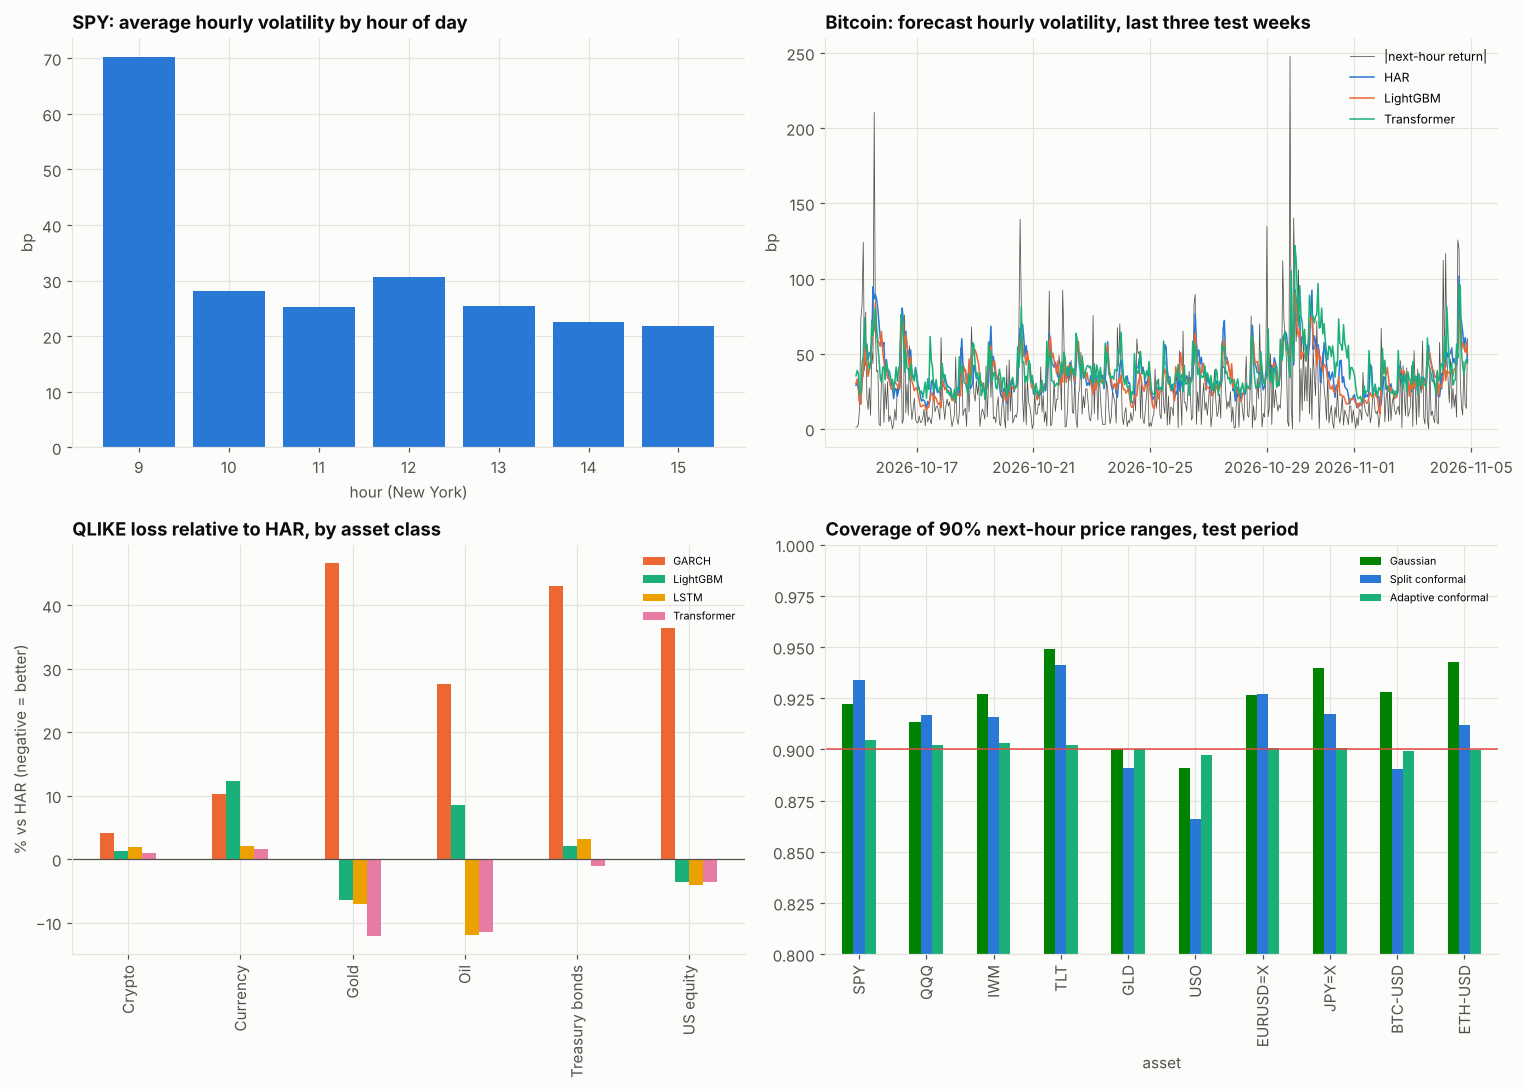

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
a = ax[0, 0]
spy = D[(D["asset"] == "SPY")]
prof = spy.groupby("next_hour")["target_r2"].mean().pow(0.5) * 1e4
a.bar(prof.index, prof.values, color=PALETTE[0])
a.set_xlabel("hour (New York)")
a.set_ylabel("bp")
a.set_title("SPY: average hourly volatility by hour of day")
a = ax[0, 1]
g = D[(D["asset"] == "BTC-USD") & T_]
w_ = slice(-24 * 21, None)
a.plot(
    g["time"].iloc[w_],
    np.sqrt(g["target_r2"].iloc[w_]) * 1e4,
    color=INK_2,
    lw=0.5,
    label="|next-hour return|",
)
for i, m in enumerate(["HAR", "LightGBM", "Transformer"]):
    a.plot(
        g["time"].iloc[w_],
        np.sqrt(FC.loc[g.index, m].iloc[w_]) * 1e4,
        color=PALETTE[i],
        lw=1,
        label=m,
    )
a.set_ylabel("bp")
a.set_title("Bitcoin: forecast hourly volatility, last three test weeks")
a.legend(fontsize=8)
a = ax[1, 0]
(BY_CLASS.drop(columns="HAR") * 100).plot.bar(ax=a, color=PALETTE[1:5])
a.axhline(0, color=INK_2, lw=0.8)
a.set_ylabel("% vs HAR (negative = better)")
a.set_title("QLIKE loss relative to HAR, by asset class")
a.legend(fontsize=7)
a = ax[1, 1]
COV_ASSET[["Gaussian", "Split conformal", "Adaptive conformal"]].plot.bar(
    ax=a,
    color=(
        PALETTE[[5, 0, 2]] if False else [PALETTE[5], PALETTE[0], PALETTE[2]]
    ),
)
a.axhline(COVER, color=STATUS["red"], lw=1)
a.set_ylim(0.8, 1.0)
a.set_title("Coverage of 90% next-hour price ranges, test period")
a.legend(fontsize=7)
fig.tight_layout()
save_fig(fig, "01_intraday_risk")
plt.show()

In [10]:
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "QLIKE vs HAR by asset class (%)",
        "Direction accuracy by asset (test)",
    ),
)
for i, m in enumerate(BY_CLASS.columns.drop("HAR")):
    dash.add_trace(
        go.Bar(
            x=BY_CLASS.index,
            y=BY_CLASS[m] * 100,
            name=m,
            marker_color=PALETTE[i + 1],
        ),
        1,
        1,
    )
dash.add_trace(
    go.Bar(
        x=DIR.index,
        y=DIR["LightGBM accuracy"],
        name="LightGBM direction",
        marker_color=PALETTE[6],
    ),
    1,
    2,
)
dash.add_trace(
    go.Bar(
        x=DIR.index,
        y=DIR["always majority"],
        name="always majority",
        marker_color=PALETTE[7],
    ),
    1,
    2,
)
dash.update_layout(
    height=600,
    width=1400,
    template="simple_white",
    barmode="group",
    title="Intraday risk forecasting across ten assets, test period",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 9. Reading the results and limitations

*Networks are seeded; the hourly data are the last two years Yahoo Finance provides, so results shift slightly as the window rolls forward.*

**Ten very different clocks.**
- **Sample:** ETFs contribute about 5,000 trading hours since December 2023, currencies about 17,000 and cryptocurrencies about 17,400 (since November 2024). The last 40% of each asset's history is the test period: from September 2025 for ETFs and currencies, from January 2026 for cryptocurrencies.
- **Volatility:** typical hourly volatility ranges from 9 basis points (EUR/USD) to 99 (USO), with gold (52) above the equity ETFs (36–51) in this period.
- **Tails:** every series is fat-tailed, with hourly kurtosis between 10 and 40.

**Volatility: a transformer edges out HAR; GARCH and LightGBM fall behind.**

| Model (test hours) | QLIKE vs HAR | Diebold–Mariano vs HAR | Mincer–Zarnowitz R² | Daily QLIKE | Daily R² |
|---|---|---|---|---|---|
| HAR with intraday seasonality | — | — | 0.161 | 0.470 | 0.777 |
| GARCH(1,1), Student-t | +16.2% | +15.4 | 0.054 | 0.467 | 0.756 |
| LightGBM (gamma) | +4.4% | +3.5 | 0.100 | 0.597 | 0.715 |
| LSTM | −0.1% | −0.2 | 0.136 | 0.483 | 0.787 |
| Transformer | −1.0% | −1.2 | 0.182 | 0.432 | 0.789 |

- **The intraday pattern is most of the signal.** GARCH, which ignores the time of day, is 16% worse than HAR hour by hour. In LightGBM the current and next hour of the day account for 39% of the gain, ahead of the 8-hour realised variance (23%). Summed over a day, where the intraday pattern washes out, GARCH is as good as HAR.
- **Transformer:** reading 48 hours of history across all assets, it had the lowest loss hourly and daily (QLIKE 0.432 against 0.470 for HAR, an 8% improvement at the daily horizon). Its hourly gain over HAR (1%) is not statistically significant (Diebold–Mariano −1.2). It gained 12% on gold and oil and 4% on equities, and lost 1–2% on currencies and cryptocurrencies.
- **LightGBM:** trained on raw squared returns with a gamma objective, it was significantly worse than HAR, especially for currencies (+12%). Its trees struggle with a target that spans six orders of magnitude.

**90% ranges: conformal calibration delivers the promised coverage.**

| Range for the next hour (transformer volatility) | Coverage, all hours | Coverage, most volatile 10% | Worst asset | Mean width |
|---|---|---|---|---|
| Gaussian (±1.645 σ̂) | 92.9% | 93.1% | 89.1% (USO) | 115 bp |
| Split conformal | 91.1% | 91.4% | 86.6% (USO) | 102 bp |
| Adaptive conformal | 90.1% | 92.0% | 89.7% (USO) | 102 bp |

- **Gaussian ranges:** they over-cover on average because the forecasts already absorb much of the tail risk, and they are 12% wider than needed.
- **Split conformal:** it fixes the average width but not every asset. Calibrated on an earlier period, it under-covered oil (86.6%) and Bitcoin (89.0%), whose behaviour changed.
- **Adaptive conformal inference:** it holds coverage between 89.7% and 90.5% for every asset with the same average width, and keeps 92% in the most volatile hours. The calibrated multipliers range from 1.35 standard deviations for cryptocurrencies to 1.74 for SPY: the right range depends on the asset's tails, not on a normal table.

**Direction: barely better than a coin, and not after costs.**
- **Accuracy:** over about 40,000 test hours with a price change, both classifiers predicted the next hour's direction correctly 51.3% of the time (AUC 0.52). That is statistically above 50% only because the sample is huge. Always predicting the direction that was more common in training scored 50.6%.
- **By asset:** the models matched or trailed that naive benchmark on all six ETFs (within 0.4 points, oil −1.4).
- **Where they did better:** on Bitcoin and Ether the logistic regression reached 52.0% and 52.0% (p < 0.001). But trading those signals hour by hour lost about 0.5 bp per hour after a 1 bp switching cost. The equity ETFs and oil showed small positive returns that are within noise over 2,000 hours.

**What this means for a trading desk.**
- **Hourly risk limits:** they should use a model with an intraday pattern. A plain GARCH misstates hourly risk by a wide margin even when its daily totals look fine. A HAR with hour-of-day effects is a strong, transparent baseline; a sequence model shared across assets can improve on it modestly, mainly for commodity ETFs.
- **Price ranges:** they should be calibrated, not assumed Gaussian. Adaptive conformal inference keeps the stated coverage per asset as markets change, at no cost in width.
- **Direction forecasts:** at the hourly horizon they should be reported against a majority-class benchmark and after costs. With these features, they add nothing a desk could trade on.

**Limitations.**
- **Data:** about two years of hourly bars from one free source, with a single 60/40 time split. Squared hourly returns are noisy proxies of variance (higher-frequency data would allow realised-variance targets), and ETF hours exclude overnight trading.
- **Models:** the networks are small and trained once, without retraining as the test period unfolds; direction models use only price-based features, no order flow or news.

In [11]:
SUMMARY.to_csv(OUT_DIR / "assets.csv")
VOLCMP.to_csv(OUT_DIR / "volatility_models.csv")
BY_CLASS.to_csv(OUT_DIR / "qlike_vs_har_by_class.csv")
DAILY.to_csv(OUT_DIR / "daily_aggregation.csv")
IMP.to_csv(OUT_DIR / "lightgbm_feature_importance.csv")
COV.to_csv(OUT_DIR / "range_coverage.csv")
COV_ASSET.to_csv(OUT_DIR / "range_coverage_by_asset.csv")
DIR.to_csv(OUT_DIR / "direction_by_asset.csv")
DIR_ALL.to_csv(OUT_DIR / "direction_overall.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_intraday_risk.png, assets.csv, daily_aggregation.csv, dashboard.html, dashboard.png, direction_by_asset.csv, direction_overall.csv, lightgbm_feature_importance.csv, qlike_vs_har_by_class.csv, range_coverage.csv, range_coverage_by_asset.csv, volatility_models.csv


## References

- Andersen, T. G., & Bollerslev, T. (1997). Intraday periodicity and volatility persistence in financial markets. *Journal of Empirical Finance*, 4(2–3), 115–158. https://doi.org/10.1016/S0927-5398(97)00004-2
- Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics*, 31(3), 307–327. https://doi.org/10.1016/0304-4076(86)90063-1
- Corsi, F. (2009). A simple approximate long-memory model of realized volatility. *Journal of Financial Econometrics*, 7(2), 174–196. https://doi.org/10.1093/jjfinec/nbp001
- Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253–263. https://doi.org/10.1080/07350015.1995.10524599
- Gibbs, I., & Candès, E. (2021). Adaptive conformal inference under distribution shift. In *Advances in Neural Information Processing Systems 34* (pp. 1660–1672).
- Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*, 9(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735
- Patton, A. J. (2011). Volatility forecast comparison using imperfect volatility proxies. *Journal of Econometrics*, 160(1), 246–256. https://doi.org/10.1016/j.jeconom.2010.03.034
- Vovk, V., Gammerman, A., & Shafer, G. (2005). *Algorithmic learning in a random world*. Springer.